# Hackathon – Dataset C (COVID vaccine) · Notebook 02 of 09
## EDA part 1 – overview, target, missing values, data quality, train/test shift

**Module:** 7PAM2002 – University of Hertfordshire · **GitHub:** `<add link>` · **Colab:** `<add link>` · **Author of this notebook:** `<name>`

**Goal of the project:** predict which residents will accept a COVID vaccine and decide who to post a dose to so that the town's **total
cost (vaccines + hospitalisations)** is as small as possible.

<details><summary><b>The nine notebooks (run them in this order)</b></summary>

| # | Notebook | Content |
|---|---|---|
| 01 | `01_Problem_Framing_and_Cost_Metric.ipynb` | Problem framing and the task-specific cost metric |
| 02 | `02_EDA_Data_Quality.ipynb` | EDA part 1 – overview, target, missing values, data quality, train/test shift |
| 03 | `03_EDA_Feature_Relationships.ipynb` | EDA part 2 – distributions, associations, interactions, cost drivers |
| 04 | `04_Preprocessing.ipynb` | Pre-processing – cleaning, feature engineering, comparing four options |
| 05 | `05_Model_Tuning.ipynb` | Modelling – six model families and hyper-parameter tuning |
| 06 | `06_Cross_Validation_and_Decision_Strategy.ipynb` | Repeated cross-validation and turning probabilities into decisions |
| 07 | `07_Holdout_Evaluation_and_Robustness.ipynb` | Unseen hold-out evaluation, bootstrap uncertainty, robustness to assumptions |
| 08 | `08_Final_Selection_and_Submission.ipynb` | Final model selection and the five ranked submission files |
| 09 | `09_Explainable_AI_and_Conclusions.ipynb` | Explainable AI (SHAP, odds ratios, permutation importance) and conclusions |

Shared code (data loading, cost metric, cleaning, pipelines, models, evaluation helpers) lives in **`hackathon_utils.py`** so every notebook uses
exactly the same definitions. Results are passed from one notebook to the next through the **`artifacts/`** folder.
</details>


In [1]:
# ---- Set-up: run from the repository folder locally, or in Google Colab ----
import sys, os, subprocess, importlib, importlib.util
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/<your-organisation>/<your-repository>.git'   # <- set this once for Colab

if IN_COLAB and not Path('hackathon_utils.py').exists():
    subprocess.run(['git', 'clone', '-q', REPO_URL, 'repo'], check=True)   # get code, data and artifacts
    os.chdir('repo')

for pkg in ['xgboost', 'lightgbm', 'catboost', 'shap']:                    # CatBoost is not pre-installed on Colab
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from hackathon_utils import *            # shared data, cost metric, pipelines, models and helpers
print('train:', train_raw.shape, '| test:', test_raw.shape, '| scikit-learn', sklearn.__version__)

train: (4756, 31) | test: (4749, 30) | scikit-learn 1.6.1


In [2]:
from sklearn.metrics import roc_auc_score

## 3. Exploratory Data Analysis – part 1
### 3.1 Overview, types and basic statistics

In [3]:
overview = pd.DataFrame({
    'dtype': train_raw[FEATURES].dtypes.astype(str),
    'n_unique': train_raw[FEATURES].nunique(),
    'missing_train_%': (train_raw[FEATURES].isna().mean() * 100).round(1),
    'missing_test_%': (test_raw[FEATURES].isna().mean() * 100).round(1),
    'example_values': [list(train_raw[c].dropna().unique()[:4]) for c in FEATURES],
})
overview['group'] = ['binary' if c in BINARY else 'ordinal/count' if c in ORDINAL_NUM else 'categorical' for c in FEATURES]
print('Duplicated respondent ids:', train_raw[ID].duplicated().sum(),
      '| duplicated feature rows:', train_raw[FEATURES].duplicated().sum(),
      '| id overlap train/test:', len(set(train_raw[ID]) & set(test_raw[ID])))
overview.sort_values('missing_train_%', ascending=False)

Duplicated respondent ids: 0 | duplicated feature rows: 0 | id overlap train/test: 0


,dtype,n_unique,missing_train_%,missing_test_%,example_values,group
employment_sector,object,21,49.0,50.6,"[construction, education, wholesale, science]",categorical
health_insurance,float64,2,40.1,41.7,"[1.0, 0.0]",binary
income_poverty,object,3,15.7,16.8,"[<= $75,000, Above Poverty, > $75,000, Below P...",categorical
rent_or_own,object,2,6.9,8.0,"[Own, Rent]",categorical
employment_status,object,3,5.0,5.8,"[Employed, Not in Labor Force, Unemployed]",categorical
marital_status,object,2,4.9,5.7,"[Married, Not Married]",categorical
education,object,4,4.8,5.7,"[12 Years, College Graduate, Some College, < 1...",categorical
child_under_6_months,float64,2,2.8,3.3,"[0.0, 1.0]",binary
health_worker,float64,2,2.8,3.1,"[0.0, 1.0]",binary
opinion_covid_sick_from_vacc,float64,5,1.9,2.3,"[2.0, 1.0, 5.0, 4.0]",ordinal/count


In [4]:
train_raw[BINARY + ORDINAL_NUM + [TARGET]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
behavioral_antiviral_meds,4742.0,0.05,0.22,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4729.0,0.73,0.44,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4754.0,0.07,0.26,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4747.0,0.84,0.37,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4746.0,0.36,0.48,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4742.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4735.0,0.69,0.46,0.0,0.0,1.0,1.0,1.0
doctor_recc_covid,4756.0,0.23,0.42,0.0,0.0,0.0,0.0,1.0
child_under_6_months,4621.0,0.09,0.29,0.0,0.0,0.0,0.0,1.0
health_worker,4624.0,0.14,0.35,0.0,0.0,0.0,0.0,1.0


### 3.2 The target

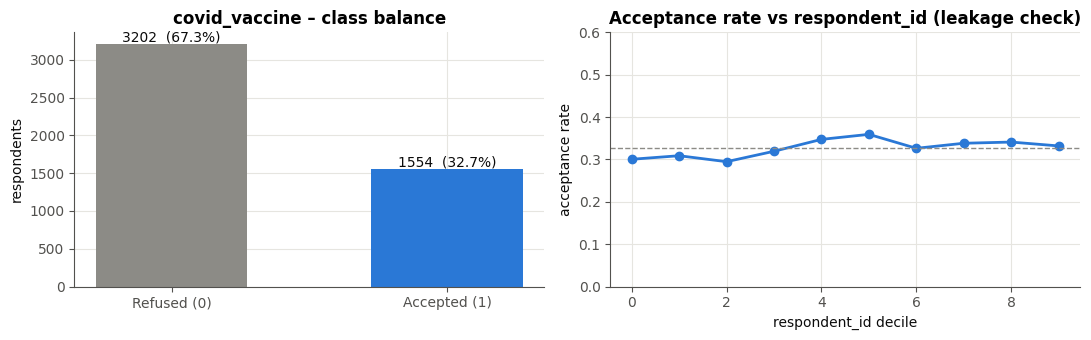

AUC of respondent_id alone: 0.515


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
counts = train_raw[TARGET].value_counts().sort_index()
axes[0].bar(['Refused (0)', 'Accepted (1)'], counts.values, color=[GREY, BLUE], width=0.55)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 40, f'{v}  ({v / counts.sum():.1%})', ha='center', color=INK)
axes[0].set_title('covid_vaccine – class balance'); axes[0].set_ylabel('respondents')

# Is the (random) respondent id predictive?  It should not be – check for ordering/leakage.
binned = pd.qcut(train_raw[ID], 10, labels=False)
axes[1].plot(train_raw.groupby(binned)[TARGET].mean().values, marker='o', color=BLUE, lw=2)
axes[1].axhline(train_raw[TARGET].mean(), color=GREY, ls='--', lw=1)
axes[1].set_ylim(0, 0.6); axes[1].set_xlabel('respondent_id decile'); axes[1].set_ylabel('acceptance rate')
axes[1].set_title('Acceptance rate vs respondent_id (leakage check)')
plt.tight_layout(); savefig('03_target'); plt.show()
print('AUC of respondent_id alone:', round(roc_auc_score(train_raw[TARGET], train_raw[ID]), 3))

* **≈33 % accept** the vaccine – a moderate imbalance. We will **not** re-balance (SMOTE / class weights) because that would distort the
  predicted probabilities, and our decision rule needs *calibrated* probabilities. The cost-based threshold handles the imbalance instead.
* `respondent_id` carries no signal (AUC ≈ 0.5, flat deciles), so it is dropped as a feature.

### 3.3 Missing values – how much, where, and are they informative?

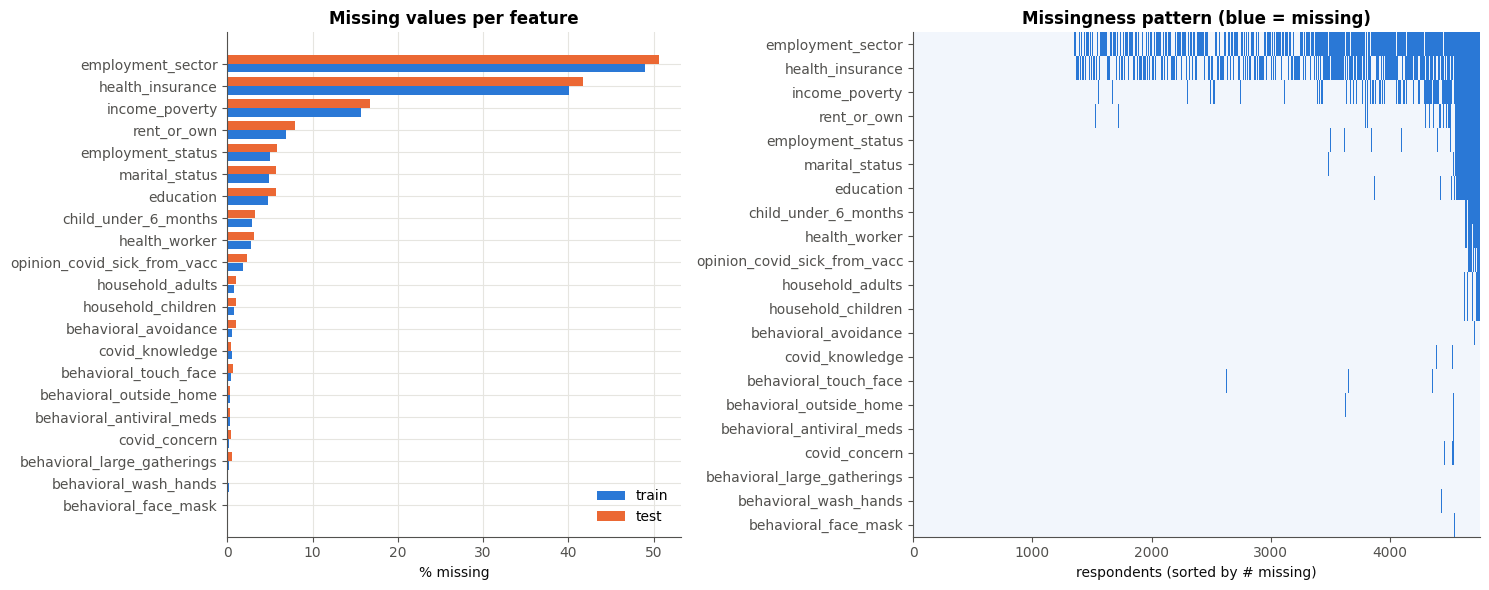

In [6]:
miss = pd.DataFrame({'train': train_raw[FEATURES].isna().mean(), 'test': test_raw[FEATURES].isna().mean()}) * 100
miss = miss[miss.max(axis=1) > 0].sort_values('train')

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1, 1.25]})
y_pos = np.arange(len(miss))
axes[0].barh(y_pos - 0.2, miss['train'], height=0.38, color=BLUE, label='train')
axes[0].barh(y_pos + 0.2, miss['test'], height=0.38, color=ORANGE, label='test')
axes[0].set_yticks(y_pos, miss.index); axes[0].set_xlabel('% missing'); axes[0].legend(loc='lower right')
axes[0].set_title('Missing values per feature')

# Missingness matrix: rows sorted by number of missing values -> shows that missingness is clustered
order = train_raw[FEATURES].isna().sum(axis=1).sort_values().index
mat = train_raw.loc[order, miss.index[::-1]].isna().to_numpy().T
axes[1].imshow(mat, aspect='auto', cmap=LinearSegmentedColormap.from_list('m', ['#f2f6fc', BLUE]), interpolation='nearest')
axes[1].set_yticks(range(len(miss)), miss.index[::-1]); axes[1].set_xlabel('respondents (sorted by # missing)')
axes[1].set_title('Missingness pattern (blue = missing)'); axes[1].grid(False)
plt.tight_layout(); savefig('03_missing'); plt.show()

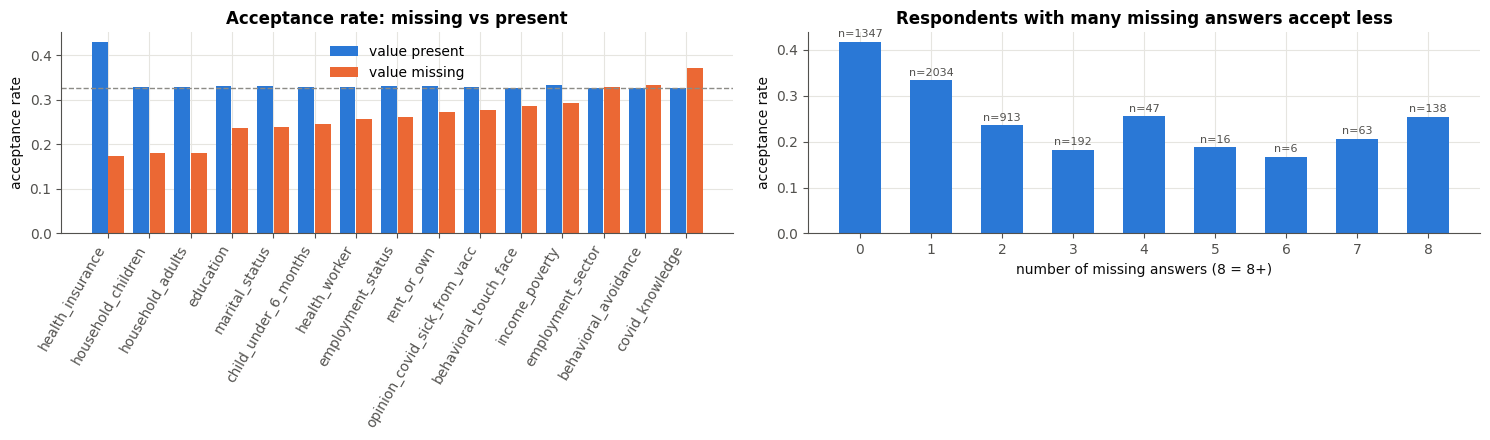

,feature,n_missing,rate_if_missing,rate_if_present
13,health_insurance,1908,0.173,0.430
3,household_children,39,0.179,0.328
4,household_adults,39,0.179,0.328
8,education,228,0.237,0.331
9,marital_status,231,0.238,0.331
7,child_under_6_months,135,0.244,0.329
6,health_worker,132,0.258,0.329
10,employment_status,238,0.261,0.330
11,rent_or_own,329,0.274,0.331
5,opinion_covid_sick_from_vacc,90,0.278,0.328


In [7]:
# Is "being missing" related to the target?  Compare acceptance rate when the value is missing vs present.
rows = []
for c in miss.index:
    is_na = train_raw[c].isna()
    if is_na.sum() >= 20:
        rows.append({'feature': c, 'n_missing': int(is_na.sum()),
                     'rate_if_missing': train_raw.loc[is_na, TARGET].mean(),
                     'rate_if_present': train_raw.loc[~is_na, TARGET].mean()})
mt = pd.DataFrame(rows).sort_values('rate_if_missing')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
x = np.arange(len(mt))
axes[0].bar(x - 0.2, mt['rate_if_present'], 0.38, color=BLUE, label='value present')
axes[0].bar(x + 0.2, mt['rate_if_missing'], 0.38, color=ORANGE, label='value missing')
axes[0].set_xticks(x, mt['feature'], rotation=60, ha='right'); axes[0].set_ylabel('acceptance rate')
axes[0].axhline(train_raw[TARGET].mean(), color=GREY, ls='--', lw=1); axes[0].legend()
axes[0].set_title('Acceptance rate: missing vs present')

n_miss = train_raw[FEATURES].isna().sum(axis=1).clip(upper=8)
g = train_raw.groupby(n_miss)[TARGET].agg(['mean', 'size'])
axes[1].bar(g.index.astype(str), g['mean'], color=BLUE, width=0.6)
for i, (m, n) in enumerate(zip(g['mean'], g['size'])):
    axes[1].text(i, m + 0.01, f'n={n}', ha='center', fontsize=8, color=INK2)
axes[1].set_xlabel('number of missing answers (8 = 8+)'); axes[1].set_ylabel('acceptance rate')
axes[1].set_title('Respondents with many missing answers accept less')
plt.tight_layout(); savefig('03_missing_vs_target'); plt.show()
mt.round(3)

**Findings on missingness**
* `employment_sector` (≈49 %) and `health_insurance` (≈40 %) are heavily missing; most other features < 10 %.
* Missingness is **not random**: people who skip `health_insurance`, `income_poverty`, `health_worker`… accept the vaccine *less often*
  (e.g. ~17 % vs ~43 % for health insurance). Respondents with many skipped answers are less engaged and less likely to accept.
* ⇒ Dropping rows or blindly mean-imputing would throw away signal. We will test **"missing" as its own category + missing-indicator flags**.

### 3.4 Data-quality problems hidden in the values

In [8]:
# 1) Opinion scales are documented as 1-5, yet some rows contain 0
for c in OPINION:
    vc = train_raw[c].value_counts(dropna=False).sort_index()
    print(f'{c:32s}', dict(vc))
zero_rows = train_raw[OPINION[:2]].eq(0).any(axis=1)
print('\nMean # of missing answers | opinion == 0:', round(train_raw.loc[zero_rows, FEATURES].isna().sum(axis=1).mean(), 2),
      ' vs others:', round(train_raw.loc[~zero_rows, FEATURES].isna().sum(axis=1).mean(), 2))

# 2) employment_sector is missing *by design* for people who are not employed
print('\nemployment_sector missing, by employment_status:')
print(pd.crosstab(train_raw['employment_status'].fillna('(missing)'), train_raw['employment_sector'].isna(),
                  colnames=['sector missing']))

# 3) doctor_recc_covid has no missing values at all, unlike every other survey answer (missing probably coded as 0)
print('\ndoctor_recc_covid missing values:', train_raw['doctor_recc_covid'].isna().sum())

opinion_covid_vacc_effective     {0: np.int64(92), 1: np.int64(124), 2: np.int64(241), 3: np.int64(772), 4: np.int64(2425), 5: np.int64(1102)}
opinion_covid_risk               {0: np.int64(96), 1: np.int64(1196), 2: np.int64(1228), 3: np.int64(982), 4: np.int64(1029), 5: np.int64(225)}
opinion_covid_sick_from_vacc     {1.0: np.int64(2115), 2.0: np.int64(1358), 3.0: np.int64(10), 4.0: np.int64(876), 5.0: np.int64(307), nan: np.int64(90)}

Mean # of missing answers | opinion == 0: 8.38  vs others: 1.22

employment_sector missing, by employment_status:
sector missing      False  True 
employment_status               
(missing)               0    238
Employed             2426     25
Not in Labor Force      0   1808
Unemployed              0    259

doctor_recc_covid missing values: 0


**Data-quality decisions**
1. `opinion_covid_vacc_effective` and `opinion_covid_risk` contain **0**, which is not a valid answer (scale 1–5). Rows with a 0 have
   ~7× more missing answers than others, so **0 is a disguised missing value → recode to NaN**.
2. `employment_sector` is missing for 2 300 people **because they are not employed** – that is not "unknown", it is a real category
   → fill with `not_employed` (only the 25 employed people + people with unknown status are truly missing).
3. `opinion_covid_sick_from_vacc = 3` ("don't know") is almost never used (10 rows) – harmless, kept as ordinal.
4. `number_chronic_med_conditions` has a long tail (only 12 people with ≥4) → **top-code at 3** (a simple binning step).

### 3.5 Does the test set look like the training set? (distribution shift)

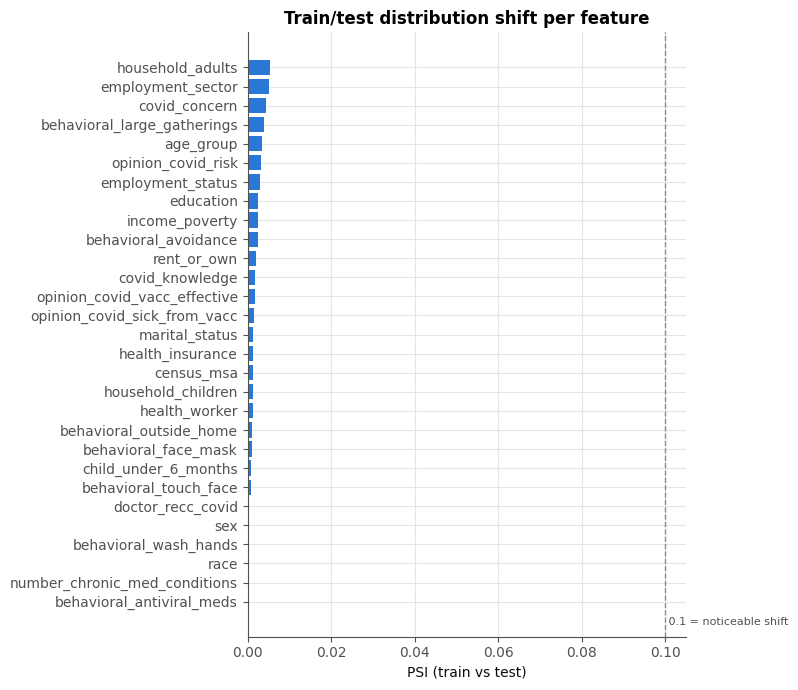

Largest PSI: household_adults 0.0053


In [9]:
def psi(a, b, eps=1e-4):
    # Population Stability Index between two samples of a discrete variable (NaN treated as a category).
    a, b = a.fillna('NaN').astype(str), b.fillna('NaN').astype(str)
    cats = sorted(set(a) | set(b))
    pa = a.value_counts(normalize=True).reindex(cats, fill_value=0) + eps
    pb = b.value_counts(normalize=True).reindex(cats, fill_value=0) + eps
    return float(((pa - pb) * np.log(pa / pb)).sum())

shift = pd.Series({c: psi(train_raw[c], test_raw[c]) for c in FEATURES}).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(shift.index, shift.values, color=[ORANGE if v > 0.1 else BLUE for v in shift.values])
ax.axvline(0.1, color=GREY, ls='--', lw=1); ax.text(0.1, -1.2, ' 0.1 = noticeable shift', color=INK2, fontsize=8)
ax.set_xlabel('PSI (train vs test)'); ax.set_title('Train/test distribution shift per feature')
plt.tight_layout(); savefig('03_shift'); plt.show()
print('Largest PSI:', shift.idxmax(), round(shift.max(), 4))

All PSI values are far below 0.1 → the test town has the **same population profile** as the training sample, so cross-validated
estimates should transfer well to the test set.

**Next:** notebook 03 looks at how each feature relates to vaccine acceptance.